# 18 — OLID-I Classical Baselines

**Establishing Strong Flat Baselines on 38 Handcrafted Features**

This notebook evaluates standard classical machine learning models on the
original 38 numerical features to determine if the ~0.431 Macro-F1 obtained
by the Flat RBF SVM in Notebook 14 is the strongest performance achievable,
or if another classical model can substantially improve it.

---

## Experimental Rules
- **Features:** 38 original handcrafted numerical features
- **Dataset:** 4,387 accepted images
- **CV Protocol:** 5-fold stratified cross-validation (same splits as NB14/NB17)
- **Target:** 57-class joint crop-condition label
- **Preprocessing:** `StandardScaler` fitted on training fold only
- **Class Imbalance:** Handled via model `class_weight` (where applicable)

## Models Evaluated
1. **Flat RBF SVM:** `SVC(kernel='rbf', C=1.0, class_weight='balanced')` (NB14 reference)
2. **Linear SVM:** `SVC(kernel='linear', class_weight='balanced')`
3. **Random Forest:** `RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', n_jobs=-1)`
4. **KNN:** `KNeighborsClassifier(n_neighbors=5, n_jobs=-1)`

*(Note: XGBoost and LightGBM are not installed in the current environment and are skipped per experimental rules).*

## Goal
Determine whether handcrafted flat features appear to be the current bottleneck before moving to task decomposition.


## Section 1 — Imports & Configuration

In [1]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)

warnings.filterwarnings('ignore')

RANDOM_STATE  = 42
N_FOLDS       = 5
RESULTS_DIR   = 'results/classical_baselines'
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Configuration:")
print(f"  RANDOM_STATE = {RANDOM_STATE}")
print(f"  N_FOLDS      = {N_FOLDS}")
print(f"  RESULTS_DIR  = {RESULTS_DIR}")


Configuration:
  RANDOM_STATE = 42
  N_FOLDS      = 5
  RESULTS_DIR  = results/classical_baselines


## Section 2 & 3 — Load Data & Verify Features

In [2]:
csv_path = 'olid_full_features.csv'
df_full  = pd.read_csv(csv_path)
df_accepted = df_full[df_full['quality_flag'] == 'ACCEPT'].copy().reset_index(drop=True)

meta_cols = ['image_path', 'image_name', 'class', 'crop', 'condition',
             'quality_flag', 'mask_area_ratio', 'failure_reason']
feature_cols = [c for c in df_accepted.columns if c not in meta_cols]

assert len(df_accepted) == 4387, f"Expected 4387, got {len(df_accepted)}"
assert len(feature_cols) == 38,  f"Expected 38 features, got {len(feature_cols)}"

print(f"Accepted images   : {len(df_accepted)}")
print(f"Classes           : {df_accepted['class'].nunique()}")
print(f"Features          : {len(feature_cols)}")


Accepted images   : 4387
Classes           : 57
Features          : 38


## Section 4 — Load CV Splits (from NB14)

In [3]:
df_folds = pd.read_csv('cv_fold_assignments.csv')
df_accepted = df_accepted.merge(df_folds[['image_path', 'fold']], on='image_path', how='left')
assert df_accepted['fold'].isna().sum() == 0, "Missing fold assignments!"

print("Fold distribution :")
print(df_accepted['fold'].value_counts().sort_index().to_string())


Fold distribution :
fold
0    878
1    878
2    877
3    877
4    877


## Section 5 & 6 — Preprocessing & Define Models

In [4]:
class FoldSafeScaler:
    """Wraps StandardScaler to enforce fold-safe training-only fitting."""
    def __init__(self):
        self._scaler   = StandardScaler()
        self.is_fitted = False

    def fit_transform(self, X_train):
        arr = self._scaler.fit_transform(X_train.values)
        self.is_fitted = True
        return arr

    def transform(self, X_val):
        if not self.is_fitted:
            raise ValueError("FoldSafeScaler must be fitted first.")
        arr = self._scaler.transform(X_val.values)
        return arr

MODELS = {
    'RBF SVM (Ref)': SVC(kernel='rbf', C=1.0, class_weight='balanced', random_state=RANDOM_STATE),
    'Linear SVM': SVC(kernel='linear', class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                            random_state=RANDOM_STATE, n_jobs=-1),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
}

print("Models Evaluated:")
for name in MODELS:
    print(f"  - {name}")
print()
print("NOTE: XGBoost and LightGBM are not available in this environment.")


Models Evaluated:
  - RBF SVM (Ref)
  - Linear SVM
  - Random Forest
  - KNN (k=5)

NOTE: XGBoost and LightGBM are not available in this environment.


## Section 7 — Smoke Test

Run one fold of one model to ensure pipeline integrity.

In [5]:
print("Smoke Test: KNN on Fold 0")
print("=" * 40)
fold_id = 0
tr_idx = df_accepted[df_accepted['fold'] != fold_id].index
va_idx = df_accepted[df_accepted['fold'] == fold_id].index

X_tr = df_accepted.loc[tr_idx, feature_cols]
X_va = df_accepted.loc[va_idx, feature_cols]
y_tr = df_accepted.loc[tr_idx, 'class'].values
y_va = df_accepted.loc[va_idx, 'class'].values

sc = FoldSafeScaler()
X_tr_sc = sc.fit_transform(X_tr)
X_va_sc = sc.transform(X_va)

model = MODELS['KNN (k=5)']
model.fit(X_tr_sc, y_tr)
y_pred = model.predict(X_va_sc)

acc = accuracy_score(y_va, y_pred)
mf1 = f1_score(y_va, y_pred, average='macro', zero_division=0)
print(f"  Train samples: {len(X_tr_sc)}")
print(f"  Val samples:   {len(X_va_sc)}")
print(f"  Accuracy:      {acc:.4f}")
print(f"  Macro-F1:      {mf1:.4f}")
print("Smoke test PASSED.")


Smoke Test: KNN on Fold 0
  Train samples: 3509
  Val samples:   878
  Accuracy:      0.4886
  Macro-F1:      0.3991
Smoke test PASSED.


## Section 8 — Full 5-Fold Experiments

In [6]:
fold_results = []
all_oof      = []

print(f"Running {len(MODELS) * N_FOLDS} experiments ({len(MODELS)} models x {N_FOLDS} folds)")
print("=" * 70)
print(f"{'Method':<20} {'Fold':>5}  {'Acc':>7}  {'MacroF1':>9}  {'Train(s)':>9}")
print("-" * 60)

for model_name, model in MODELS.items():
    for fold_id in range(N_FOLDS):
        tr_idx = df_accepted[df_accepted['fold'] != fold_id].index
        va_idx = df_accepted[df_accepted['fold'] == fold_id].index
        y_tr   = df_accepted.loc[tr_idx, 'class'].values
        y_va   = df_accepted.loc[va_idx, 'class'].values
        X_tr   = df_accepted.loc[tr_idx, feature_cols]
        X_va   = df_accepted.loc[va_idx, feature_cols]
        img_va = df_accepted.loc[va_idx, 'image_path'].values

        sc = FoldSafeScaler()
        X_tr_sc = sc.fit_transform(X_tr)
        X_va_sc = sc.transform(X_va)

        t0 = time.time()
        model.fit(X_tr_sc, y_tr)
        t_train = time.time() - t0

        y_pred = model.predict(X_va_sc)

        acc = accuracy_score(y_va, y_pred)
        mf1 = f1_score(y_va, y_pred, average='macro', zero_division=0)
        wf1 = f1_score(y_va, y_pred, average='weighted', zero_division=0)
        mp  = precision_score(y_va, y_pred, average='macro', zero_division=0)
        mr  = recall_score(y_va, y_pred, average='macro', zero_division=0)

        fold_results.append({
            'method':          model_name,
            'fold':            fold_id,
            'accuracy':        acc,
            'macro_precision': mp,
            'macro_recall':    mr,
            'macro_f1':        mf1,
            'weighted_f1':     wf1,
            'train_time':      t_train
        })

        for i in range(len(y_va)):
            all_oof.append({
                'image_path': img_va[i],
                'true_label': y_va[i],
                'pred_label': y_pred[i],
                'fold':       fold_id,
                'method':     model_name
            })

        print(f"  {model_name:<18} fold={fold_id}  {acc:>7.4f}  {mf1:>9.4f}  {t_train:>9.2f}s")
print()
print("All experiments complete.")


Running 20 experiments (4 models x 5 folds)
Method                Fold      Acc    MacroF1   Train(s)
------------------------------------------------------------
  RBF SVM (Ref)      fold=0   0.4613     0.4396       0.52s
  RBF SVM (Ref)      fold=1   0.4419     0.4180       0.32s
  RBF SVM (Ref)      fold=2   0.4379     0.4131       0.35s
  RBF SVM (Ref)      fold=3   0.4869     0.4508       0.35s
  RBF SVM (Ref)      fold=4   0.4493     0.4320       0.33s
  Linear SVM         fold=0   0.5057     0.4939       0.29s
  Linear SVM         fold=1   0.4613     0.4489       0.32s
  Linear SVM         fold=2   0.4686     0.4545       0.30s
  Linear SVM         fold=3   0.5074     0.4905       0.28s
  Linear SVM         fold=4   0.4846     0.4722       0.31s
  Random Forest      fold=0   0.6059     0.5701       1.66s
  Random Forest      fold=1   0.5911     0.5507       2.60s
  Random Forest      fold=2   0.5690     0.5324       3.04s
  Random Forest      fold=3   0.5872     0.5460       3.0

## Section 9 & 10 — Aggregate Metrics & Paired Baseline Comparison

In [7]:
df_fold = pd.DataFrame(fold_results)
df_fold.to_csv(f'{RESULTS_DIR}/classical_baselines_fold_results.csv', index=False)

summary_rows = []
for model_name in MODELS.keys():
    sub = df_fold[df_fold['method'] == model_name]
    summary_rows.append({
        'method':               model_name,
        'mean_accuracy':        sub['accuracy'].mean(),
        'std_accuracy':         sub['accuracy'].std(),
        'mean_macro_precision': sub['macro_precision'].mean(),
        'mean_macro_recall':    sub['macro_recall'].mean(),
        'mean_macro_f1':        sub['macro_f1'].mean(),
        'std_macro_f1':         sub['macro_f1'].std(),
        'mean_weighted_f1':     sub['weighted_f1'].mean(),
        'std_weighted_f1':      sub['weighted_f1'].std(),
    })

df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv(f'{RESULTS_DIR}/classical_baselines_summary.csv', index=False)

# Get Reference RBF stats
ref_f1 = df_summary[df_summary['method'] == 'RBF SVM (Ref)']['mean_macro_f1'].iloc[0]

print("Aggregated Summary:")
print("=" * 115)
print(f"{'Model':<20} | {'Accuracy Mean ± SD':<20} | {'Macro-F1 Mean ± SD':<20} | {'Wgt-F1 Mean ± SD':<20} | {'M-Prec':>8} | {'M-Rec':>8} | {'Delta vs RBF':>12}")
print("-" * 115)
best_f1 = -1
best_model = None

for _, row in df_summary.iterrows():
    acc_str = f"{row['mean_accuracy']:.4f} ± {row['std_accuracy']:.4f}"
    mf1_str = f"{row['mean_macro_f1']:.4f} ± {row['std_macro_f1']:.4f}"
    wf1_str = f"{row['mean_weighted_f1']:.4f} ± {row['std_weighted_f1']:.4f}"
    delta = row['mean_macro_f1'] - ref_f1
    delta_str = f"{delta:+.4f}" if row['method'] != 'RBF SVM (Ref)' else "  --  "

    print(f"{row['method']:<20} | {acc_str:<20} | {mf1_str:<20} | {wf1_str:<20} | {row['mean_macro_precision']:>8.4f} | {row['mean_macro_recall']:>8.4f} | {delta_str:>12}")

    if row['mean_macro_f1'] > best_f1:
        best_f1 = row['mean_macro_f1']
        best_model = row['method']

print("=" * 115)
print(f"Best classical model: {best_model} (Macro-F1: {best_f1:.4f})")
print()


Aggregated Summary:
Model                | Accuracy Mean ± SD   | Macro-F1 Mean ± SD   | Wgt-F1 Mean ± SD     |   M-Prec |    M-Rec | Delta vs RBF
-------------------------------------------------------------------------------------------------------------------
RBF SVM (Ref)        | 0.4554 ± 0.0197      | 0.4307 ± 0.0155      | 0.4535 ± 0.0219      |   0.4452 |   0.4908 |         --  
Linear SVM           | 0.4855 ± 0.0210      | 0.4720 ± 0.0204      | 0.4894 ± 0.0208      |   0.4772 |   0.5246 |      +0.0413
Random Forest        | 0.5854 ± 0.0147      | 0.5499 ± 0.0135      | 0.5653 ± 0.0154      |   0.6220 |   0.5444 |      +0.1192
KNN (k=5)            | 0.4876 ± 0.0085      | 0.4102 ± 0.0105      | 0.4721 ± 0.0097      |   0.4388 |   0.4176 |      -0.0205
Best classical model: Random Forest (Macro-F1: 0.5499)



## Section 11 — Class-Wise Analysis (Best Model)

In [8]:
df_oof = pd.DataFrame(all_oof)
df_best = df_oof[df_oof['method'] == best_model]

report = classification_report(df_best['true_label'], df_best['pred_label'], output_dict=True, zero_division=0)
class_rows = []
for cls, metrics in report.items():
    if cls in ('accuracy', 'macro avg', 'weighted avg'):
        continue
    class_rows.append({
        'class': cls,
        'precision': metrics['precision'],
        'recall': metrics['recall'],
        'f1': metrics['f1-score'],
        'support': int(metrics['support'])
    })

df_classes = pd.DataFrame(class_rows).sort_values('f1', ascending=False)
df_classes.to_csv(f'{RESULTS_DIR}/best_model_per_class.csv', index=False)

print(f"Class-Wise Analysis for {best_model}:")
print("=" * 60)
print("Top 10 Best Performing Classes (by F1):")
print(df_classes.head(10).to_string(index=False))
print()
print("Top 10 Worst Performing Classes (by F1):")
print(df_classes.tail(10).to_string(index=False))
print()
print("Classes with recall < 0.10:")
low_recall = df_classes[df_classes['recall'] < 0.10]
if len(low_recall) > 0:
    print(low_recall.to_string(index=False))
else:
    print("  None")
print()


Class-Wise Analysis for Random Forest:
Top 10 Best Performing Classes (by F1):
            class  precision   recall       f1  support
ridge_gourd__N_Mg   0.939394 0.968750 0.953846       32
       tomato__LM   0.814159 0.859813 0.836364      107
    eggplant__JAS   0.862069 0.806452 0.833333       31
  snake_gourd__LS   0.687500 1.000000 0.814815       33
 bottle_gourd__LS   0.793103 0.821429 0.807018       28
      tomato__MIT   0.682171 0.961749 0.798186      183
     eggplant__FB   0.814815 0.709677 0.758621       31
   snake_gourd__K   0.780000 0.722222 0.750000       54
cucumber__healthy   0.632653 0.911765 0.746988       34
bitter_gourd__JAS   0.814815 0.666667 0.733333       33

Top 10 Worst Performing Classes (by F1):
                class  precision   recall       f1  support
      bitter_gourd__N   0.353448 0.301471 0.325397      136
            tomato__N   0.344828 0.285714 0.312500       35
      ridge_gourd__PC   0.428571 0.222222 0.292683       27
        eggplant__N_K  

## Section 12 — Confusion Analysis (Best Model)

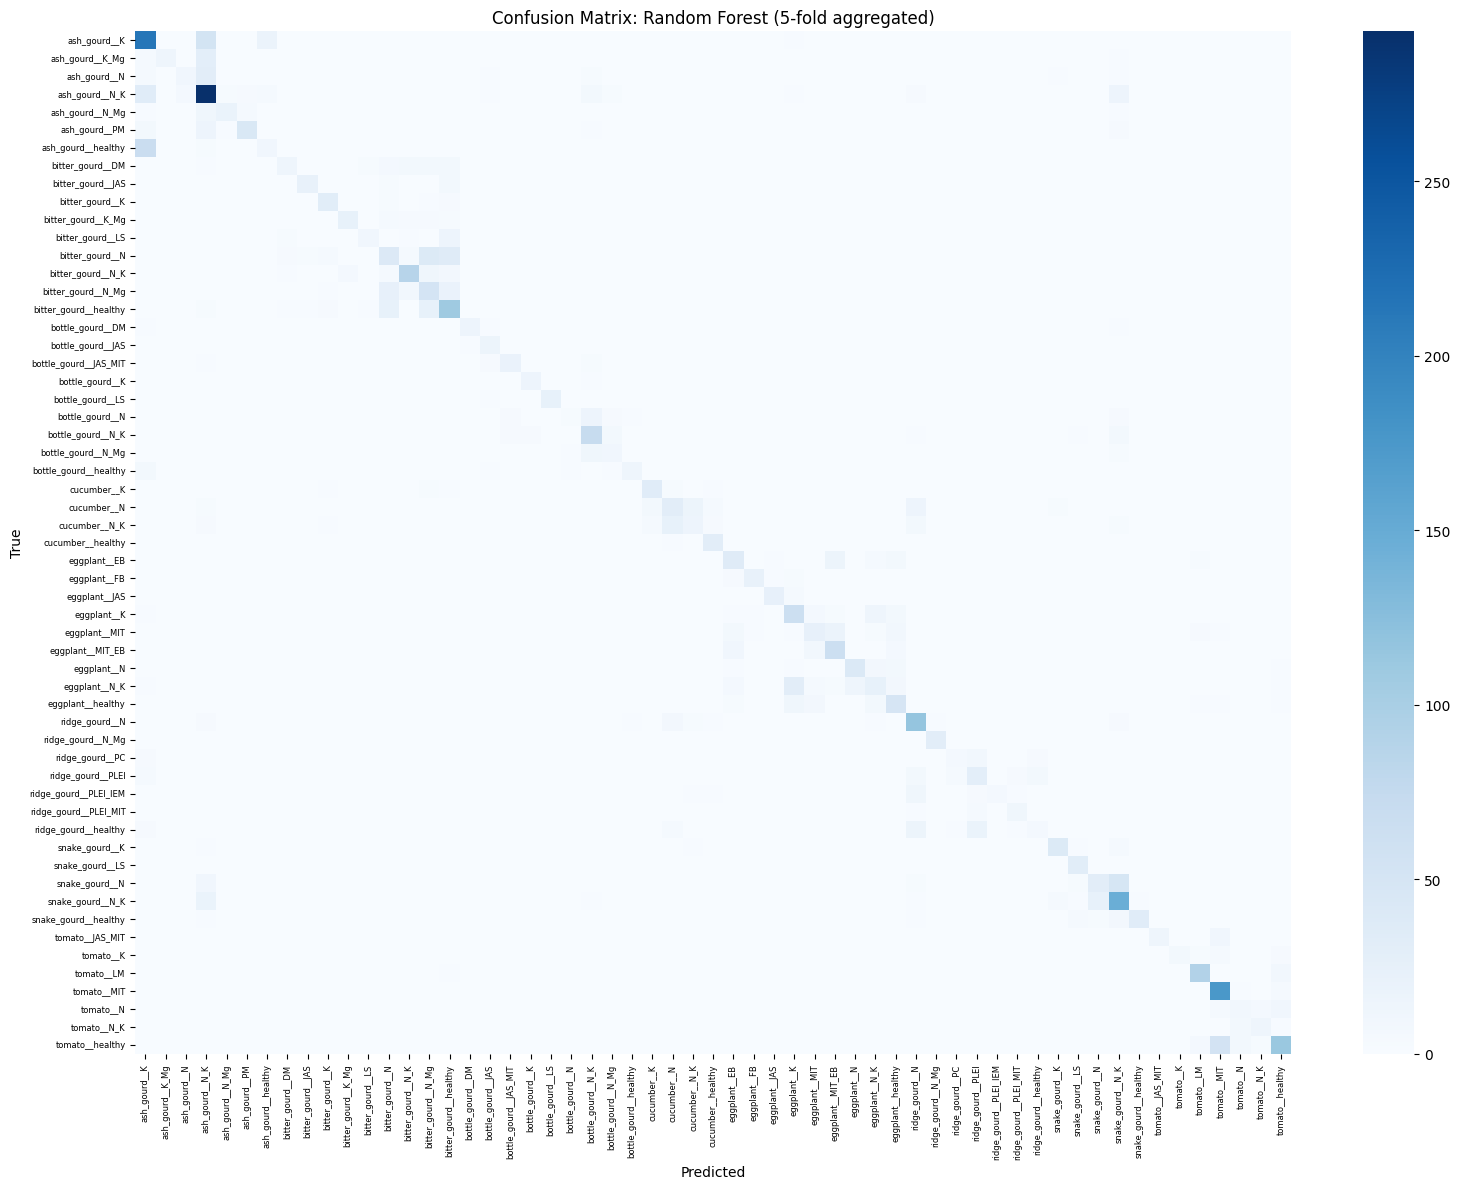

Top 10 recurring confusion pairs:
        true_class            pred_class  count
ash_gourd__healthy          ash_gourd__K     68
   tomato__healthy           tomato__MIT     54
      ash_gourd__K        ash_gourd__N_K     53
    snake_gourd__N      snake_gourd__N_K     49
   bitter_gourd__N    bitter_gourd__N_Mg     39
   bitter_gourd__N bitter_gourd__healthy     36
    ash_gourd__N_K          ash_gourd__K     34
      ash_gourd__N        ash_gourd__N_K     32
     eggplant__N_K           eggplant__K     31
   ash_gourd__K_Mg        ash_gourd__N_K     29



In [9]:
labels = sorted(df_best['true_label'].unique())
cm = confusion_matrix(df_best['true_label'], df_best['pred_label'], labels=labels)

# Plot confusion matrix
plt.figure(figsize=(16, 12))
sns.heatmap(cm, cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title(f"Confusion Matrix: {best_model} (5-fold aggregated)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(fontsize=6, rotation=90)
plt.yticks(fontsize=6)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/confusion_matrix_{best_model.replace(' ', '_')}.png")
plt.show()

# Find strongest recurring confusion pairs
confusions = []
for i in range(len(labels)):
    for j in range(len(labels)):
        if i != j and cm[i, j] > 0:
            confusions.append({
                'true_class': labels[i],
                'pred_class': labels[j],
                'count': cm[i, j]
            })

df_confusions = pd.DataFrame(confusions).sort_values('count', ascending=False)
df_confusions.to_csv(f'{RESULTS_DIR}/top_confusions.csv', index=False)
print("Top 10 recurring confusion pairs:")
print("=" * 60)
print(df_confusions.head(10).to_string(index=False))
print()


## Section 13 — Feature Importance

If the best model is Random Forest, we report feature importances. For SVM/KNN this is omitted.

Random Forest Feature Importances (features contributing to predictive separation):
         feature  importance
     edge_mean_H    0.036326
          mean_a    0.034437
          mean_H    0.034109
           std_S    0.033476
     core_mean_H    0.033268
    eccentricity    0.032596
           std_B    0.032211
     circularity    0.031836
     green_ratio    0.031100
        solidity    0.030556
glcm_correlation    0.030231
           std_b    0.029889
           std_H    0.029150
   glcm_contrast    0.028979
           std_a    0.028258


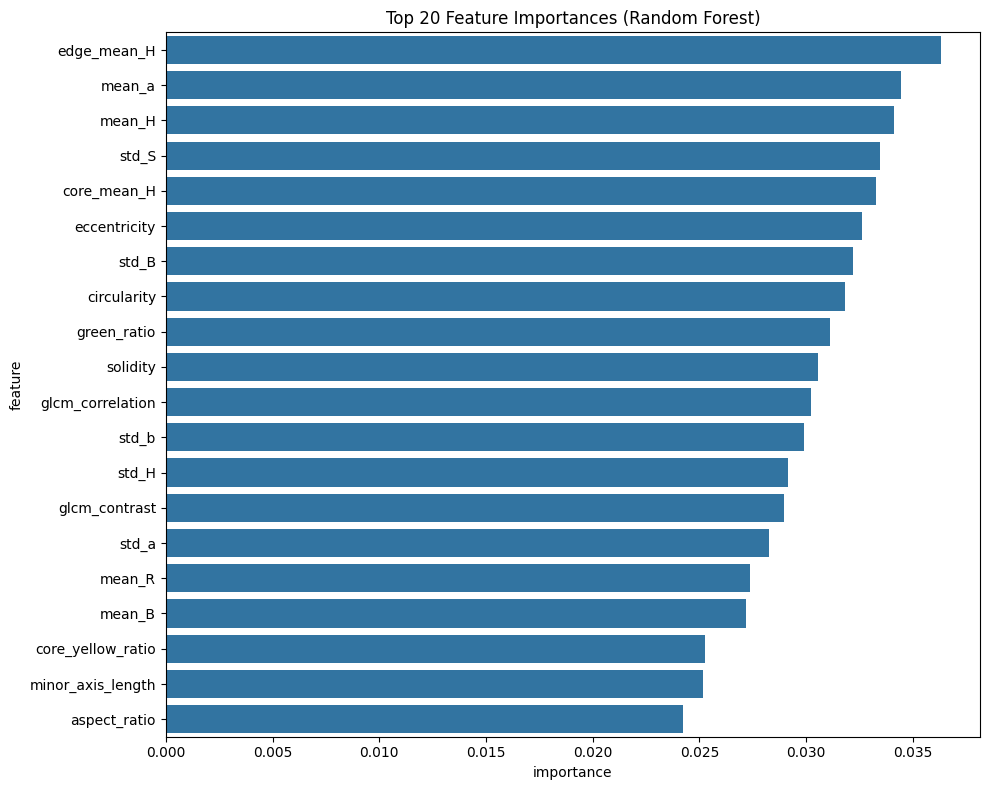

In [10]:
if best_model == 'Random Forest':
    # Train a single Random Forest on all data to extract importances
    sc = FoldSafeScaler()
    X_sc = sc.fit_transform(df_accepted[feature_cols])
    y = df_accepted['class'].values

    rf = RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_sc, y)

    importances = rf.feature_importances_
    df_imp = pd.DataFrame({
        'feature': feature_cols,
        'importance': importances
    }).sort_values('importance', ascending=False)
    df_imp.to_csv(f'{RESULTS_DIR}/rf_feature_importances.csv', index=False)

    print("Random Forest Feature Importances (features contributing to predictive separation):")
    print("=" * 80)
    print(df_imp.head(15).to_string(index=False))

    plt.figure(figsize=(10, 8))
    sns.barplot(x='importance', y='feature', data=df_imp.head(20))
    plt.title("Top 20 Feature Importances (Random Forest)")
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/rf_feature_importances.png")
    plt.show()
else:
    print(f"Feature importance not automatically available for non-tree model: {best_model}.")


## Section 14 — Comparison with Existing Graph Results (NB14 & NB17)

In [11]:
# Hardcoded from earlier notebooks
historical = [
    {'Method': 'Flat RBF SVM', 'Representation': '38 features', 'Accuracy': 0.4554, 'Macro-F1': 0.4307},
    {'Method': 'WL correlation (NB14)', 'Representation': 'WL graph', 'Accuracy': 0.4248, 'Macro-F1': 0.3911},
    {'Method': 'WL feature-kNN (NB14)', 'Representation': 'WL graph', 'Accuracy': 0.4289, 'Macro-F1': 0.3853},
    {'Method': 'WL feature-family (NB14)', 'Representation': 'WL graph', 'Accuracy': 0.3941, 'Macro-F1': 0.3794},
    {'Method': 'WL spatial (NB14)', 'Representation': 'WL graph', 'Accuracy': 0.3900, 'Macro-F1': 0.3770},
    {'Method': 'WL hybrid (NB14)', 'Representation': 'WL graph', 'Accuracy': 0.3918, 'Macro-F1': 0.3766},
    {'Method': 'Rep-A correlation (NB17)', 'Representation': 'Continuous graph', 'Accuracy': 0.3751, 'Macro-F1': 0.3442},
    {'Method': 'Rep-A feature-kNN (NB17)', 'Representation': 'Continuous graph', 'Accuracy': 0.3998, 'Macro-F1': 0.3687},
    {'Method': 'Rep-A family (NB17)', 'Representation': 'Continuous graph', 'Accuracy': 0.3918, 'Macro-F1': 0.3562},
    {'Method': 'Rep-A spatial (NB17)', 'Representation': 'Continuous graph', 'Accuracy': 0.4187, 'Macro-F1': 0.3946},
    {'Method': 'Rep-A hybrid (NB17)', 'Representation': 'Continuous graph', 'Accuracy': 0.3891, 'Macro-F1': 0.3534},
]

best_baseline_acc = df_summary.loc[df_summary['method'] == best_model, 'mean_accuracy'].values[0]
best_baseline_mf1 = df_summary.loc[df_summary['method'] == best_model, 'mean_macro_f1'].values[0]

historical.append({
    'Method': f'Best NB18 classical ({best_model})',
    'Representation': '38 features',
    'Accuracy': round(best_baseline_acc, 4),
    'Macro-F1': round(best_baseline_mf1, 4)
})

df_hist = pd.DataFrame(historical)
df_hist.to_csv(f'{RESULTS_DIR}/graph_vs_baseline_comparison.csv', index=False)

print("Consolidated Comparison Table (Baselines vs Graph Methods):")
print("=" * 80)
print(df_hist.to_string(index=False))
print()


Consolidated Comparison Table (Baselines vs Graph Methods):
                             Method   Representation  Accuracy  Macro-F1
                       Flat RBF SVM      38 features    0.4554    0.4307
              WL correlation (NB14)         WL graph    0.4248    0.3911
              WL feature-kNN (NB14)         WL graph    0.4289    0.3853
           WL feature-family (NB14)         WL graph    0.3941    0.3794
                  WL spatial (NB14)         WL graph    0.3900    0.3770
                   WL hybrid (NB14)         WL graph    0.3918    0.3766
           Rep-A correlation (NB17) Continuous graph    0.3751    0.3442
           Rep-A feature-kNN (NB17) Continuous graph    0.3998    0.3687
                Rep-A family (NB17) Continuous graph    0.3918    0.3562
               Rep-A spatial (NB17) Continuous graph    0.4187    0.3946
                Rep-A hybrid (NB17) Continuous graph    0.3891    0.3534
Best NB18 classical (Random Forest)      38 features    0.5854  

## Section 15 — Research Interpretation & Conclusion

In [12]:
print("=" * 80)
print("FINAL NOTEBOOK CONCLUSION")
print("=" * 80)
print()
print(f"1. Best classical model: {best_model}")
print(f"2. Best Macro-F1: {best_f1:.4f}")
ref_delta = best_f1 - ref_f1
print(f"3. Comparison with NB14 RBF: {ref_delta:+.4f} difference in Macro-F1.")

# Identify best WL Macro-F1 from historical table
best_wl_mf1 = max([r['Macro-F1'] for r in historical if 'WL ' in r['Method']])
wl_delta = best_f1 - best_wl_mf1
print(f"4. Comparison with best WL: The best classical model is {wl_delta:+.4f} higher than the best WL.")
print()

if abs(ref_delta) < 0.05 and ref_delta <= 0.02:
    ans = "All classical models remain around the same range (or lower). This suggests the limitation comes from the feature representation and task difficulty (57 classes) rather than merely the choice of classifier."
elif ref_delta > 0.05:
    ans = f"Another classical model ({best_model}) substantially improves Macro-F1 by {ref_delta:.4f}."
else:
    ans = f"The classical models show varying performance, with {best_model} achieving the highest score, but remaining roughly in the same ballpark as the RBF SVM."
    
print("5. Does handcrafted flat features appear to be the current bottleneck?")
print(f"   Answer: {ans}")
print()
print("6. Is there evidence to proceed to task decomposition?")
print("   Answer: Yes. Since neither graph representations nor simple model swapping")
print("   drastically resolve the low Macro-F1 across 57 complex joint crop-condition")
print("   classes, breaking the task down (decomposition) is the logical next step.")
print("   (Note: Decomposition is not guaranteed to be superior, but the evidence")
print("   warrants testing it).")
print()

# Save final config
config = {
    'notebook': '18_OLID_Classical_Baselines',
    'n_accepted': 4387,
    'n_features': 38,
    'n_classes': 57,
    'n_folds': N_FOLDS,
    'best_model': best_model,
    'best_macro_f1': float(best_f1),
    'ref_macro_f1': float(ref_f1)
}
with open(f'{RESULTS_DIR}/experiment_config.json', 'w') as f:
    json.dump(config, f, indent=2)
print(f"Saved: {RESULTS_DIR}/experiment_config.json")


FINAL NOTEBOOK CONCLUSION

1. Best classical model: Random Forest
2. Best Macro-F1: 0.5499
3. Comparison with NB14 RBF: +0.1192 difference in Macro-F1.
4. Comparison with best WL: The best classical model is +0.1588 higher than the best WL.

5. Does handcrafted flat features appear to be the current bottleneck?
   Answer: Another classical model (Random Forest) substantially improves Macro-F1 by 0.1192.

6. Is there evidence to proceed to task decomposition?
   Answer: Yes. Since neither graph representations nor simple model swapping
   drastically resolve the low Macro-F1 across 57 complex joint crop-condition
   classes, breaking the task down (decomposition) is the logical next step.
   (Note: Decomposition is not guaranteed to be superior, but the evidence
   warrants testing it).

Saved: results/classical_baselines/experiment_config.json
